In [ ]:

!pip install -q "gymnasium[classic-control]" numpy matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.1/12.1 MB 52.2 MB/s eta 0:00:00


Episode: 1000 | Average reward (last 100): 46.31 | Epsilon: 0.606
Episode: 2000 | Average reward (last 100): 114.84 | Epsilon: 0.368
Episode: 3000 | Average reward (last 100): 174.35 | Epsilon: 0.223
Episode: 4000 | Average reward (last 100): 207.12 | Epsilon: 0.135
Episode: 5000 | Average reward (last 100): 319.27 | Epsilon: 0.082
Episode: 6000 | Average reward (last 100): 158.82 | Epsilon: 0.05
Episode: 7000 | Average reward (last 100): 225.44 | Epsilon: 0.05
Episode: 8000 | Average reward (last 100): 371.2 | Epsilon: 0.05
Episode: 9000 | Average reward (last 100): 270.28 | Epsilon: 0.05
Episode: 10000 | Average reward (last 100): 272.73 | Epsilon: 0.05
Episode: 11000 | Average reward (last 100): 263.21 | Epsilon: 0.05
Episode: 12000 | Average reward (last 100): 185.81 | Epsilon: 0.05
Episode: 13000 | Average reward (last 100): 284.45 | Epsilon: 0.05
Episode: 14000 | Average reward (last 100): 293.05 | Epsilon: 0.05
Episode: 15000 | Average reward (last 100): 254.34 | Epsilon: 0.05
E

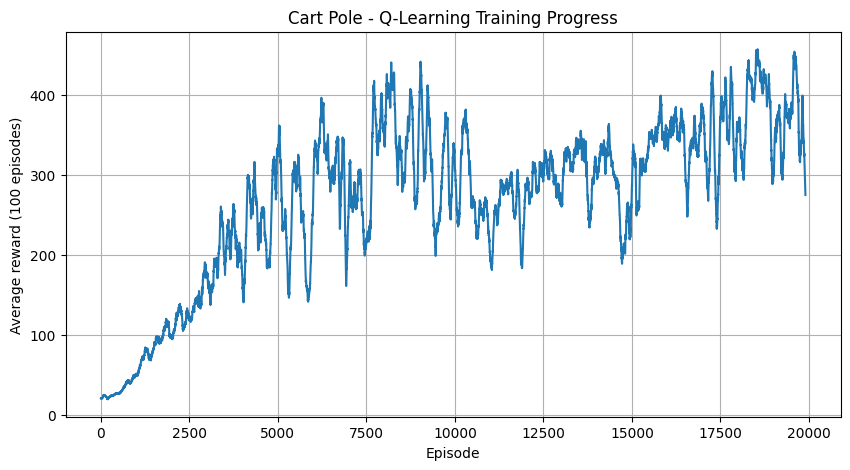

Training completed!
Q-table saved as cartpole_qtable.pkl
Graph saved as cartpole_learning_curve.png


In [ ]:

import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
import pickle

# Create the Cart Pole environment
env = gym.make("CartPole-v1")

# Number of buckets for each observation
NUM_BINS = 6

# Observation boundaries:
# cart position, cart velocity, pole angle, pole angular velocity
LOW = np.array([-2.4, -3.0, -0.2095, -3.5])
HIGH = np.array([2.4, 3.0, 0.2095, 3.5])

# Create boundaries for discretization
BINS = [
    np.linspace(LOW[i], HIGH[i], NUM_BINS + 1)[1:-1]
    for i in range(4)
]

def discretize(observation):
    state = []

    for i in range(4):
        value = np.digitize(observation[i], BINS[i])
        value = np.clip(value, 0, NUM_BINS - 1)
        state.append(value)

    return tuple(state)


# Q-table: 6 x 6 x 6 x 6 states, 2 actions
q_table = np.zeros((NUM_BINS, NUM_BINS,
                    NUM_BINS, NUM_BINS, 2))

# Learning settings
episodes = 20000
learning_rate = 0.1
discount_factor = 0.99
epsilon = 1.0
epsilon_min = 0.05
epsilon_decay = 0.9995

rewards_per_episode = []

# Training loop
for episode in range(episodes):

    observation, info = env.reset()
    state = discretize(observation)

    terminated = False
    truncated = False
    total_reward = 0

    while not (terminated or truncated):

        # Exploration or exploitation
        if np.random.random() < epsilon:
            action = env.action_space.sample()
        else:
            action = np.argmax(q_table[state])

        # Take action
        next_observation, reward, terminated, truncated, info = (
            env.step(action)
        )

        next_state = discretize(next_observation)

        # Q-learning update
        future_reward = 0 if terminated else discount_factor * np.max(
            q_table[next_state]
        )

        q_table[state + (action,)] += learning_rate * (
            reward + future_reward - q_table[state + (action,)]
        )

        state = next_state
        total_reward += reward

    rewards_per_episode.append(total_reward)

    # Gradually reduce random actions
    epsilon = max(epsilon * epsilon_decay, epsilon_min)

    if (episode + 1) % 1000 == 0:
        average = np.mean(rewards_per_episode[-100:])
        print(
            "Episode:", episode + 1,
            "| Average reward (last 100):", round(average, 2),
            "| Epsilon:", round(epsilon, 3)
        )

env.close()

# Save the trained Q-table
with open("cartpole_qtable.pkl", "wb") as file:
    pickle.dump(q_table, file)

# Plot the learning curve
moving_average = np.convolve(
    rewards_per_episode,
    np.ones(100) / 100,
    mode="valid"
)

plt.figure(figsize=(10, 5))
plt.plot(moving_average)
plt.title("Cart Pole - Q-Learning Training Progress")
plt.xlabel("Episode")
plt.ylabel("Average reward (100 episodes)")
plt.grid(True)
plt.savefig("cartpole_learning_curve.png")
plt.show()

print("Training completed!")
print("Q-table saved as cartpole_qtable.pkl")
print("Graph saved as cartpole_learning_curve.png")

In [ ]:
env = gym.make("CartPole-v1")

In [ ]:
q_table = np.zeros((6, 6, 6, 6, 2))

In [ ]:
action = env.action_space.sample()

In [ ]:
action = np.argmax(q_table[state])

In [ ]:
q_table[state + (action,)] += learning_rate * (
    reward + future_reward - q_table[state + (action,)]
)

In [ ]:
epsilon = max(epsilon * epsilon_decay, epsilon_min)

In [ ]:

import gymnasium as gym
import numpy as np
import pickle

# Load the trained Q-table
with open("cartpole_qtable.pkl", "rb") as file:
    q_table = pickle.load(file)

# Use the same discretization boundaries as training
import matplotlib.pyplot as plt

env = gym.make("CartPole-v1")

def discretize_test(observation):
    state = []

    for i in range(4):
        value = np.digitize(observation[i], BINS[i])
        value = np.clip(value, 0, NUM_BINS - 1)
        state.append(value)

    return tuple(state)

# Test the agent for 5 episodes
test_rewards = []

for episode in range(5):

    observation, info = env.reset()
    state = discretize_test(observation)

    terminated = False
    truncated = False
    total_reward = 0

    while not (terminated or truncated):

        # Choose the best learned action
        action = np.argmax(q_table[state])

        observation, reward, terminated, truncated, info = (
            env.step(action)
        )

        state = discretize_test(observation)
        total_reward += reward

    test_rewards.append(total_reward)

    print(
        "Test episode:", episode + 1,
        "| Reward:", int(total_reward)
    )

env.close()

print("Average test reward:", round(np.mean(test_rewards), 2))

Test episode: 1 | Reward: 341
Test episode: 2 | Reward: 329
Test episode: 3 | Reward: 341
Test episode: 4 | Reward: 462
Test episode: 5 | Reward: 278
Average test reward: 350.2


In [ ]:

from IPython.display import HTML, display
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import gymnasium as gym
import pickle
import numpy as np

# Load trained Q-table
with open("cartpole_qtable.pkl", "rb") as file:
    q_table = pickle.load(file)

# Create a visual environment
env = gym.make("CartPole-v1", render_mode="rgb_array")

observation, info = env.reset()
frames = []
terminated = False
truncated = False
total_reward = 0

# Record the agent's movements
while not (terminated or truncated):

    state = discretize_test(observation)
    action = np.argmax(q_table[state])

    observation, reward, terminated, truncated, info = (
        env.step(action)
    )

    total_reward += reward
    frames.append(env.render())

env.close()

print("Animation episode reward:", int(total_reward))

# Create animation
fig, ax = plt.subplots(figsize=(7, 4))
ax.axis("off")

picture = ax.imshow(frames[0])

def update(frame_index):
    picture.set_data(frames[frame_index])
    return [picture]

movie = animation.FuncAnimation(
    fig,
    update,
    frames=len(frames),
    interval=30,
    blit=True
)

plt.close(fig)

display(HTML(movie.to_jshtml()))

Animation episode reward: 469


In [ ]:
import os

print(os.path.exists("cartpole_qtable.pkl"))
print(os.getcwd())
print(os.listdir())

True
/content
['.config', 'cartpole_qtable.pkl', 'drive', 'cartpole_learning_curve.png', 'sample_data']


In [ ]:
print(q_table)
print(q_table.shape)

[[[[[ 0.          0.        ]
    [ 1.19762732  0.        ]
    [18.8270364  14.7129266 ]
    [19.70321667 17.56010099]
    [18.8218383   0.        ]
    [ 0.          0.        ]]

   [[ 0.          0.        ]
    [ 2.59007704  0.        ]
    [20.81446434 23.37567507]
    [22.68689175 17.87460501]
    [22.16425231  9.93816296]
    [ 0.          0.        ]]

   [[ 0.          0.        ]
    [ 0.          0.        ]
    [21.42814788 21.42432122]
    [23.1403231  30.31542025]
    [22.00337873  8.02113652]
    [ 0.66436182  3.68471976]]

   [[ 0.          0.        ]
    [ 0.          0.        ]
    [32.74785499 19.98562007]
    [30.34701641 32.02323252]
    [21.27183817 27.90487858]
    [ 1.88192487 19.83831651]]

   [[ 0.          0.        ]
    [ 0.          0.        ]
    [35.62810133  2.74966448]
    [23.99823876 38.73847953]
    [13.64583738 27.20566218]
    [ 1.66287464  0.126829  ]]

   [[ 0.          0.        ]
    [ 0.          0.        ]
    [23.11303474  0.        ]


In [ ]:
with open("cartpole_qtable.pkl", "wb") as file:
    pickle.dump(q_table, file)

In [ ]:
print(q_table)
print(q_table.shape)

[[[[[ 0.          0.        ]
    [ 1.19762732  0.        ]
    [18.8270364  14.7129266 ]
    [19.70321667 17.56010099]
    [18.8218383   0.        ]
    [ 0.          0.        ]]

   [[ 0.          0.        ]
    [ 2.59007704  0.        ]
    [20.81446434 23.37567507]
    [22.68689175 17.87460501]
    [22.16425231  9.93816296]
    [ 0.          0.        ]]

   [[ 0.          0.        ]
    [ 0.          0.        ]
    [21.42814788 21.42432122]
    [23.1403231  30.31542025]
    [22.00337873  8.02113652]
    [ 0.66436182  3.68471976]]

   [[ 0.          0.        ]
    [ 0.          0.        ]
    [32.74785499 19.98562007]
    [30.34701641 32.02323252]
    [21.27183817 27.90487858]
    [ 1.88192487 19.83831651]]

   [[ 0.          0.        ]
    [ 0.          0.        ]
    [35.62810133  2.74966448]
    [23.99823876 38.73847953]
    [13.64583738 27.20566218]
    [ 1.66287464  0.126829  ]]

   [[ 0.          0.        ]
    [ 0.          0.        ]
    [23.11303474  0.        ]


In [ ]:
(6, 6, 6, 6, 2)

(6, 6, 6, 6, 2)

In [ ]:
import os

print(os.path.exists("cartpole_qtable.pkl"))

True
